# From the NSDF archive to a spectrum, and a question about the baseline

One Run 76 series (`07221115_0845`, -81.7 V), the dumps fetched with `nsdf-cli` into `data/`, reduced by `goldsluice` with the definition `am-lines.dataset.toml`, and read back here with `goldpan`. The saved outputs below are from all 12 dumps (`dumps-full.txt`); with fewer dumps the numbers differ and the plots are noisier.

*The analysis approach is due to Anthony Villano. The notebook was written with the help of Claude Code.*

For every pulse in every channel `goldsluice` computed: the pulse with a line fitted to its tail subtracted (`subtract_line`), the integral of that over samples 400 to 1500 (`window_integral`), the mean of the raw trace before the pulse (`baseline`, the quantity `baseline_mean`), and the time the pulse crosses 20 % of its height (`rise_crossing`). **Nothing here is calibrated.**

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from goldpan.adapters import parquet, idx
from goldpan import channels as gc
from goldpan.config import DCRC_RUN76

HERE = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "am-lines.dataset.toml").exists())   # the folder of this repository
OUT = HERE / "output" / "am-lines"        # what `goldsluice run` wrote
RAW = HERE / "data"                       # the dumps `nsdf-cli download` fetched
q = parquet.read(OUT, detector="NAI-S2").quantities
L = "ABCDEF"
get = lambda ch, name: np.asarray(q[f"Side2p{ch}"][name], dtype=float)
window = {c: get(c, "window_integral") for c in L}      # the integral of the pulse, samples 400 to 1500, tail line subtracted
base   = {c: get(c, "baseline_mean") for c in L}        # the mean of the raw trace before the pulse (ADC counts)
cross  = {c: get(c, "crossing_time_s") * 1e6 for c in L}  # when the pulse crosses 20 % of its height (us)
trig = np.asarray(q["trigger_type"]).astype(str); dump = np.asarray(q["dump"]).astype(str); event = np.asarray(q["event"])
print(f"{len(trig):,} events in {len(set(dump))} dumps")

39,232 events in 12 dumps


## 1. The summed window integral of A + B, and a patch on the detector face
The six channels see the same pulse. Where it landed on the face is estimated from the delays between the channels' 20 % crossing times (`xdel`, `ydel`). The *patch* is the circle of radius 4.5 us around (10.4, 4.1) us in that plane, which selects one population of events.

59.5 keV peak at 0.836, width 0.058 (6.9 %): 0.01404 per keV, relative scale only


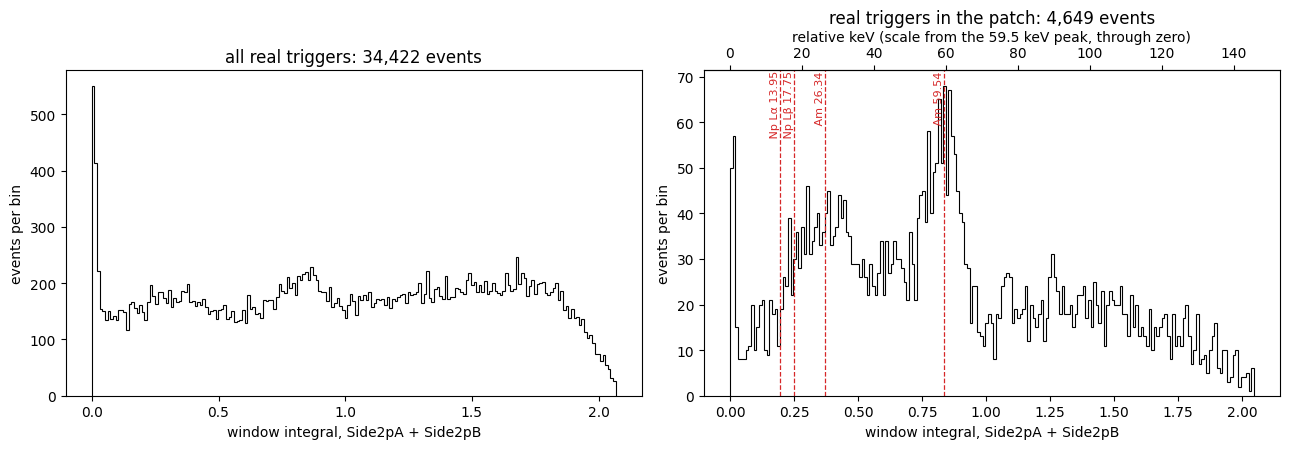

In [2]:
T = np.column_stack([cross[c] for c in L])
xdel = cross["E"] - 0.5 * (cross["C"] + cross["D"]) - 1.0          # empirical offsets in the delay plane
ydel = 0.866 * (cross["D"] - cross["C"]) + 9.0
finite = np.isfinite(T).all(axis=1)
one_pulse = (np.abs(T - np.nanmedian(np.where(finite[:, None], T, 0), axis=1, keepdims=True)) < 60).all(axis=1)
real = (trig == "Unknown") & finite & one_pulse                      # real triggers (the working assumption of goldpan.cuts)
patch = real & (np.hypot(xdel - 10.4, ydel - 4.1) < 4.5)
AB = window["A"] + window["B"]

# A relative calibration: the scale is set by the 59.5 keV peak alone, through zero (no offset, no second point).
# Fit that peak (a Gaussian on a straight line) on the patch spectrum, with plain numpy: a grid over position and width,
# the amplitude and the line solved exactly at each point.
h, edges = np.histogram(AB[patch], bins=np.arange(0, 2.2, 0.01)); x = 0.5 * (edges[1:] + edges[:-1])
sel = (x > 0.65) & (x < 1.05)
best = None
for mu in np.arange(0.75, 0.95, 0.002):
    for sg in np.arange(0.02, 0.10, 0.002):
        D = np.column_stack([np.exp(-0.5 * ((x[sel] - mu) / sg) ** 2), np.ones(sel.sum()), x[sel]])
        w = 1 / np.sqrt(np.maximum(h[sel], 1))
        coef, *_ = np.linalg.lstsq(D * w[:, None], h[sel] * w, rcond=None)
        chi2 = (((D @ coef - h[sel]) * w) ** 2).sum()
        if coef[0] > 0 and (best is None or chi2 < best[0]): best = (chi2, mu, sg)
_, mu59, sig59 = best
per_keV = mu59 / 59.54
print(f"59.5 keV peak at {mu59:.3f}, width {sig59:.3f} ({100 * sig59 / mu59:.1f} %): {per_keV:.5f} per keV, relative scale only")

LINES = {13.95: "Np Lα 13.95", 17.75: "Np Lβ 17.75", 26.34: "Am 26.34", 59.54: "Am 59.54"}     # keV
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, m, lab in [(axes[0], real, "all real triggers"), (axes[1], patch, "real triggers in the patch")]:
    ax.hist(AB[m], bins=np.linspace(0, np.percentile(AB[m], 99.7), 200), histtype="step", color="k", lw=0.8)
    ax.set_title(f"{lab}: {m.sum():,} events"); ax.set_xlabel("window integral, Side2pA + Side2pB"); ax.set_ylabel("events per bin")
ax = axes[1]
for E, name in LINES.items():
    ax.axvline(E * per_keV, color="C3", ls="--", lw=0.9)
    ax.text(E * per_keV, ax.get_ylim()[1], " " + name, rotation=90, va="top", ha="right", fontsize=8, color="C3")
sec = ax.secondary_xaxis("top", functions=(lambda v: v / per_keV, lambda e: e * per_keV)); sec.set_xlabel("relative keV (scale from the 59.5 keV peak, through zero)")
ax.set_title(f"real triggers in the patch: {patch.sum():,} events", pad=34)
fig.tight_layout(); plt.show()

With the position cut there is a peak (at about 0.84) and a hump of lines below it, but they are **smeared**. As physicists we always want our calibration peaks as sharp as possible, so: what blurs them?

The dashed lines mark the lines expected from an Am-241 source (Np L X-rays, and the 26.3 and 59.5 keV gamma rays), **assuming** the strong peak is the 59.5 keV one. There is **no energy calibration** here: the scale comes from the fitted peak alone, through zero, so the lower lines are where that scale puts them, not where they were measured.

## 2. The peak drifts downwards as the baseline rises
Look at one channel, Side2pA, for the patch events: its window integral against its own `baseline_mean` (the mean of the raw trace before the pulse). The strongest band is the one that slopes down; the red boxes (drawn by eye) mark it at a low, a middle and a high baseline.

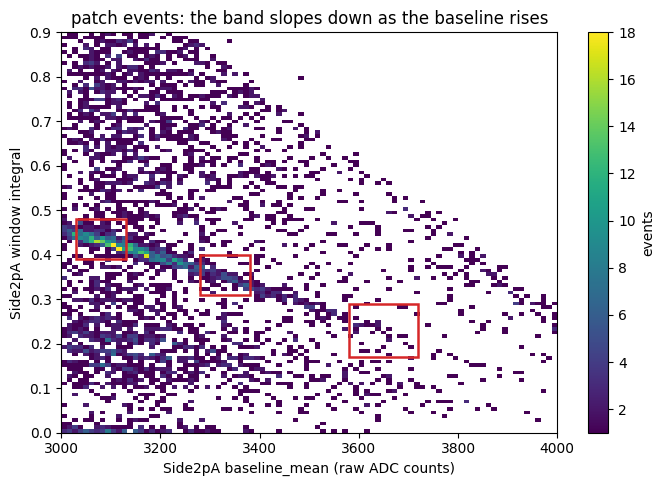

In [3]:
A_int, A_base = window["A"], base["A"]
P = np.flatnonzero(patch)

# Three boxes drawn by eye around the strong band, at a low, a middle and a high baseline: (baseline_mean range, window integral range)
BOXES = [((3030, 3130), (0.39, 0.48)), ((3280, 3380), (0.31, 0.40)), ((3580, 3720), (0.17, 0.29))]

fig, ax = plt.subplots(figsize=(8, 5.2))
h = ax.hist2d(A_base[P], A_int[P], bins=[90, 110], range=[[3000, 4000], [0, 0.9]], cmap="viridis", cmin=1)
fig.colorbar(h[3], ax=ax, label="events")
for (x0, x1), (y0, y1) in BOXES:
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="C3", lw=1.8))
ax.set_xlabel("Side2pA baseline_mean (raw ADC counts)"); ax.set_ylabel("Side2pA window integral")
ax.set_title("patch events: the band slopes down as the baseline rises")
plt.show()

Inside the red boxes the strong band falls from about 0.44 to about 0.23 over the range of baselines. A line whose integral depends on the baseline, with the baseline different from event to event, is a blurred line.

## 3. Three pulses from the same band
Because the archive gives us every trace, we can go straight to them. Take one event from each box, so at a low, a middle and a high baseline, and look at Side2pA in the raw dump files. Top: the whole trace, with the baseline estimate drawn on it (the dashed line is `baseline_mean`; the **bold black** samples are the ones it is the mean of; the shaded area between the trace and the dashed line, over samples 400 to 1500, is a picture of what the integral adds up, orange above the line and blue below it; `goldsluice` also subtracts a line fitted to the tail first, so the numbers are not exactly this area). Bottom: the samples before the pulse, the bold ones being the baseline window.

/var/folders/zw/n329d76x3rj0jv0rtrjg54k80000gq/T/ipykernel_73808/1759341674.py:7: UserWarning: sensor_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and channels 0 to 3 = board inputs pA to pD is assumed; not yet confirmed against the run's ODB
  chmap = {c.name: (c.detector, c.channel) for c in gc.sensor_channels()}      # goldpan's channel map (still under development)


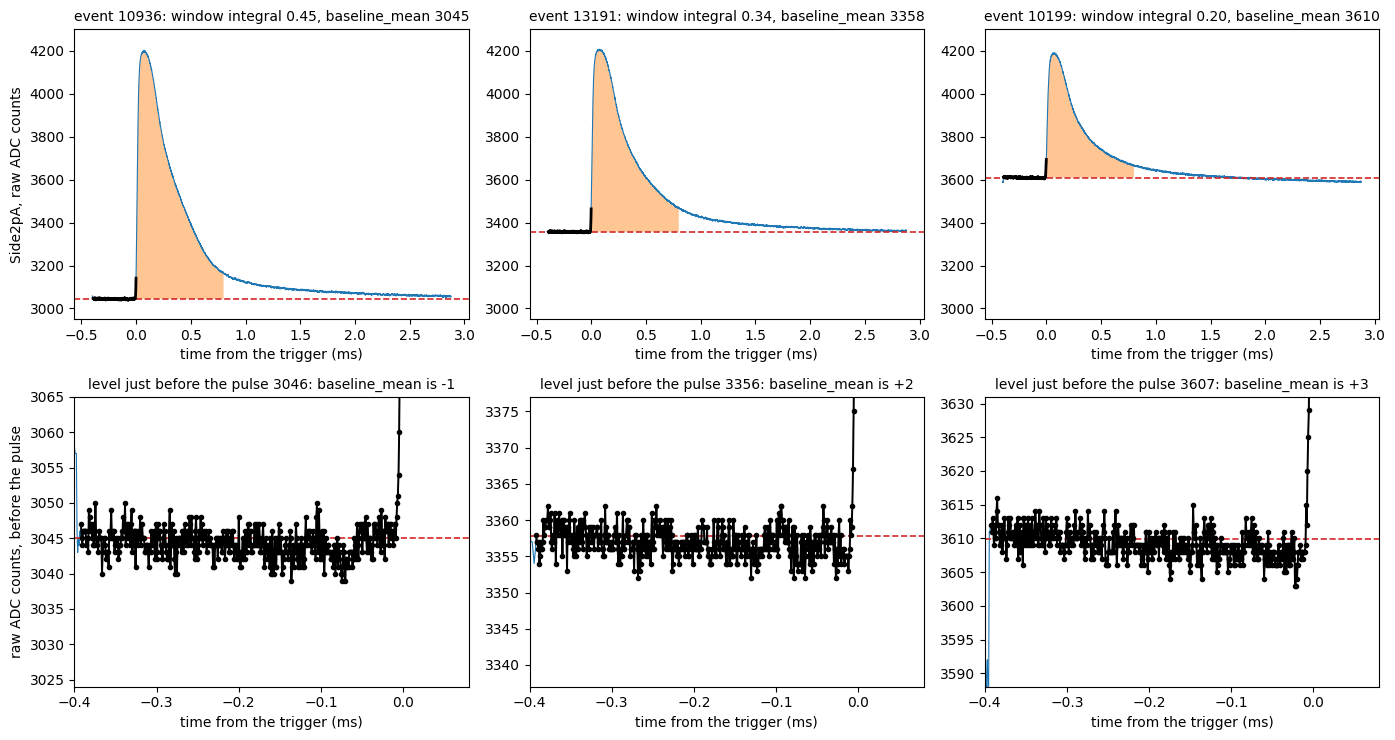

In [4]:
rng = np.random.default_rng(5)
chosen = []
for (x0, x1), (y0, y1) in BOXES:                                                      # one of the events in each box
    inside = P[(A_base[P] > x0) & (A_base[P] < x1) & (A_int[P] > y0) & (A_int[P] < y1)]
    chosen.append(int(rng.choice(inside)))

chmap = {c.name: (c.detector, c.channel) for c in gc.sensor_channels()}      # goldpan's channel map (still under development)
cache = {}
def trace(i, ch="Side2pA"):
    if dump[i] not in cache:
        cache[dump[i]] = idx.read(RAW / f"07221115_0845_{dump[i]}", detector_name="NAI-S2", config=DCRC_RUN76, channels=chmap)
    ev = cache[dump[i]]
    row = int(np.where(np.asarray(ev.quantities["event"]) == event[i])[0][0])
    return np.asarray(ev.trace(ch))[row], np.asarray(ev.time_axis()) * 1e3

INT = (400, 1500)                # the samples `window_integral` adds up
WIN = (10, 500)                  # the samples `baseline_mean` averages (glitch_samples to pretrigger_samples of the readout)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for col, i in enumerate(chosen):
    y, t = trace(i); b = A_base[i]; level = y[470:485].mean()                    # the level the pulse starts from
    for row in (0, 1):
        ax = axes[row, col]
        ax.plot(t, y, color="C0", lw=0.8); ax.axhline(b, color="C3", ls="--", lw=1.2)
        sl = slice(*INT)                                                               # the area the integral measures, against the baseline
        if row == 0:
            ax.fill_between(t[sl], y[sl], b, where=y[sl] >= b, color="C1", alpha=0.45, lw=0)
            ax.fill_between(t[sl], y[sl], b, where=y[sl] < b, color="C0", alpha=0.45, lw=0)
        w = slice(*WIN)                                                                # the samples baseline_mean is the mean of: bold
        ax.plot(t[w], y[w], color="k", lw=2.0 if row == 0 else 1.4, marker="o" if row else None, ms=3)
    axes[0, col].set_title(f"event {event[i]}: window integral {A_int[i]:.2f}, baseline_mean {b:.0f}", fontsize=10)
    axes[1, col].set_xlim(t[0], t[WIN[1]] + 0.08); axes[1, col].set_xlabel("time from the trigger (ms)")
    axes[1, col].set_title(f"level just before the pulse {level:.0f}: baseline_mean is {b - level:+.0f}", fontsize=10)
    axes[0, col].set_xlabel("time from the trigger (ms)")
axes[0, 0].set_ylabel("Side2pA, raw ADC counts"); axes[1, 0].set_ylabel("raw ADC counts, before the pulse")
for col, i in enumerate(chosen):
    y, t = trace(i); before = y[WIN[0]:480]
    axes[0, col].set_ylim(2950, 4300)                                          # the same scale on the whole traces
    axes[1, col].set_ylim(before.min() - 15, before.max() + 15)                # the zoom follows the samples before the pulse
fig.tight_layout(); plt.show()

**What the traces show.** Same band, three baselines. In each, the dashed line sits on the level the trace has just before the pulse (within a few counts), so the estimate is a fair description of that stretch. But the three pulses top out at about the same ADC value, so the higher the baseline the smaller the shaded area above the dashed line: its height above the baseline falls from about 1150 counts to about 600. The area the integral adds up is measured from the dashed line, so it depends on where that line is, and that is different from event to event. After the shaded window the third trace also comes back to the line and goes below it, by about 20 counts at the end of the trace, while the first two settle above it. This is why the next step is a better baseline estimate, and it is the slope in the plot above.

All of this, from the archive to the raw samples behind a single peak, took a few commands and a few lines of Python.

---
The data are from the NSDF dark matter dataset. It has no licence yet; the guidelines ask that you cite Roberts et al., *The Making of a Community Dark Matter Dataset with the National Science Data Fabric*, arXiv:2507.13297 (2025).